# Proyek Analisis Data: Bike Sharing Dataset (Capital Bikeshare, Washington D.C. 2011–2012)
- **Nama:** Daniel
- **Email:** ds234b6y0405@student.devacademy.id
- **ID Dicoding:** DS234B6Y0405

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah framework untuk merumuskan pertanyaan secara terstruktur (*Specific, Measurable, Action-oriented, Relevant, Time-bound*) agar analisis fokus dan hasilnya bisa langsung dipakai untuk mengambil keputusan.

Konteks bisnis: operator bike sharing perlu tahu **siapa** penggunanya, **kapan** permintaan memuncak, dan **kondisi apa** yang menurunkan permintaan, agar promosi, penempatan armada, dan jadwal perawatan tepat sasaran.

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata jumlah penyewaan sepeda **harian** antara **hari kerja** dan **hari libur/akhir pekan** untuk pengguna **casual** dan **registered** selama periode **Januari 2011 – Desember 2012**, sehingga tim marketing tahu segmen mana yang tepat menjadi target promo akhir pekan?
- **Pertanyaan 2:** Pada **jam berapa** rata-rata penyewaan sepeda per jam mencapai **puncak** pada hari kerja dibandingkan hari libur/akhir pekan sepanjang **tahun 2012**, sebagai dasar penjadwalan redistribusi armada dan perawatan sepeda?
- **Pertanyaan 3:** Berapa **persen penurunan** rata-rata penyewaan harian saat cuaca **hujan/salju ringan** dibandingkan cuaca **cerah** pada masing-masing **musim** selama **2011–2012**, untuk menentukan kebijakan jumlah armada yang disiagakan saat cuaca buruk?

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Hari kerja vs libur, per tipe pengguna | Jam puncak, hari kerja vs libur | Cuaca × musim |
| Measurable | Rata-rata sewa/hari & proporsi (%) | Rata-rata sewa/jam | Rata-rata sewa/hari & % penurunan |
| Action-oriented | Menentukan target promo | Jadwal redistribusi & perawatan | Jumlah armada saat cuaca buruk |
| Relevant | Pertumbuhan pengguna | Ketersediaan sepeda saat jam sibuk | Efisiensi operasional |
| Time-bound | Jan 2011 – Des 2012 | Tahun 2012 | Jan 2011 – Des 2012 |

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

# Palet konsisten di seluruh notebook & dashboard (biru vs oranye aman untuk buta warna)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b8b6ae"

## Data Wrangling

### Gathering Data

Dataset berisi data penyewaan sepeda Capital Bikeshare (Washington D.C.) tahun 2011–2012 dalam dua tingkat agregasi:
- `day.csv` → agregat **harian** (dipakai untuk Pertanyaan 1 & 3).
- `hour.csv` → agregat **per jam** (dipakai untuk Pertanyaan 2 dan analisis lanjutan).

#### Load tabel `day_df`

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


#### Load tabel `hour_df`

In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Ukuran day_df :", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)

Ukuran day_df : (731, 16)
Ukuran hour_df: (17379, 17)


**Insight:**
- `day_df` berisi **731 baris** (setiap hari selama 2 tahun) dan `hour_df` berisi **17.379 baris** dengan 16–17 kolom.
- Target utama adalah `cnt` (total penyewaan) yang merupakan penjumlahan `casual` (pengguna tidak terdaftar) dan `registered` (pengguna terdaftar/member).
- Kolom kategorikal (`season`, `yr`, `weathersit`, `weekday`) masih berbentuk kode angka, dan kolom cuaca (`temp`, `atemp`, `hum`, `windspeed`) masih dalam bentuk **ternormalisasi** (0–1), sehingga perlu diubah agar mudah dibaca.

### Assessing Data

#### Menilai tipe data dan missing value pada `day_df`

In [5]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [6]:
print("Missing value day_df:\n", day_df.isna().sum().sum())
print("Duplikat day_df   :", day_df.duplicated().sum())

Missing value day_df:
 0
Duplikat day_df   : 0


#### Menilai tipe data dan missing value pada `hour_df`

In [7]:
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [8]:
print("Missing value hour_df:", hour_df.isna().sum().sum())
print("Duplikat hour_df    :", hour_df.duplicated().sum())

Missing value hour_df: 0
Duplikat hour_df    : 0


**Steps to Take:**
- Kolom `dteday` bertipe `object` → harus diubah menjadi `datetime` agar bisa dianalisis sebagai deret waktu.
- Tidak ada missing value (NaN) maupun data duplikat, sehingga tidak perlu penghapusan baris.

#### Menilai *invalid value* dengan statistik deskriptif

In [9]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [10]:
print("Baris day_df dengan hum = 0 :", (day_df["hum"] == 0).sum())
print("Baris hour_df dengan hum = 0:", (hour_df["hum"] == 0).sum())
hour_df[hour_df["hum"] == 0]["dteday"].value_counts()

Baris day_df dengan hum = 0 : 1
Baris hour_df dengan hum = 0: 22


dteday
2011-03-10    22
Name: count, dtype: int64

**Steps to Take:**
- Kelembapan (`hum`) bernilai **0** (0%) tidak masuk akal secara fisik untuk udara luar ruangan, apalagi seluruhnya terjadi pada satu tanggal (**2011-03-10**, 1 baris harian dan 22 baris per jam). Ini adalah **invalid value** akibat kegagalan pencatatan sensor.
- Solusi: ubah `hum = 0` menjadi `NaN`, lalu isi dengan **interpolasi linear** berdasarkan urutan waktu (nilai hari/jam sebelum dan sesudahnya).

#### Menilai *inaccurate value* pada kolom `season`

Dokumentasi dataset (Readme) menyebut `season` 1 = *springer* (spring), 2 = summer, 3 = fall, 4 = winter. Kita cek apakah ini sesuai dengan tanggal sebenarnya.

In [11]:
season_check = (day_df.assign(dteday=pd.to_datetime(day_df["dteday"]))
                .assign(bulan_hari=lambda x: x["dteday"].dt.strftime("%m-%d"))
                .groupby("season")["bulan_hari"].agg(["min", "max"]))
season_check

,min,max
season,,
1,01-01,12-31
2,03-21,06-20
3,06-21,09-22
4,09-23,12-20


In [12]:
# Bulan apa saja yang termasuk season = 1?
sorted(day_df.loc[day_df["season"] == 1, "mnth"].unique())

[np.int64(1), np.int64(2), np.int64(3), np.int64(12)]

**Steps to Take:**
- `season = 1` berisi tanggal **21 Desember – 20 Maret** (bulan 1, 2, 3, dan 12). Di Washington D.C. (belahan bumi utara) periode ini adalah **musim dingin (Winter)**, bukan *spring* seperti di Readme. Label pada Readme tidak akurat (**inaccurate value** pada dokumentasi).
- Solusi: gunakan pemetaan yang sesuai tanggal: **1 = Winter (Dingin), 2 = Spring (Semi), 3 = Summer (Panas), 4 = Fall (Gugur)**.

#### Menilai konsistensi kolom (*inconsistent value*)

In [13]:
dt = pd.to_datetime(day_df["dteday"])
print("weekday tidak konsisten dengan tanggal :", ((dt.dt.dayofweek + 1) % 7 != day_df["weekday"]).sum())
print("casual + registered != cnt (day)       :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())
print("casual + registered != cnt (hour)      :", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())

total_per_hari = hour_df.groupby("dteday")["cnt"].sum()
print("Total per jam != total harian          :", (total_per_hari.values != day_df.set_index("dteday").loc[total_per_hari.index, "cnt"].values).sum())

weekday tidak konsisten dengan tanggal : 0
casual + registered != cnt (day)       : 0
casual + registered != cnt (hour)      : 0
Total per jam != total harian          : 0


**Insight:**
- Kolom `weekday` konsisten dengan tanggal (0 = Minggu, 6 = Sabtu), `casual + registered = cnt` di kedua tabel, dan total per jam sama persis dengan total harian. Data antar tabel **konsisten**.

#### Menilai kelengkapan data per jam (*missing records*)

In [14]:
jam_per_hari = hour_df.groupby("dteday").size()
print("Seharusnya ada  :", len(jam_per_hari) * 24, "baris")
print("Yang tercatat   :", len(hour_df), "baris")
print("Jam yang hilang :", len(jam_per_hari) * 24 - len(hour_df))
jam_per_hari.sort_values().head(5)

Seharusnya ada  : 17544 baris
Yang tercatat   : 17379 baris
Jam yang hilang : 165


dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
dtype: int64

**Steps to Take:**
- Ada **165 jam** yang tidak tercatat. Karena total per jam tetap sama dengan total harian, jam yang hilang kemungkinan besar adalah jam **tanpa penyewaan** atau saat sistem tidak beroperasi (contoh: 2012-10-29 hanya punya 1 jam data, bertepatan dengan **Badai Sandy**).
- Solusi: baris **tidak diisi dengan angka karangan**, karena kita tidak tahu apakah nilainya benar-benar 0 atau sistem mati. Dampaknya kecil (<1% data) dan akan dicatat sebagai keterbatasan analisis per jam.

#### Menilai *outlier* dengan metode IQR

In [15]:
def hitung_outlier(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for kolom in ["cnt", "casual", "registered"]:
    print(f"Outlier {kolom:<11}: {hitung_outlier(day_df[kolom])}")

Outlier cnt        : 0
Outlier casual     : 44
Outlier registered : 0


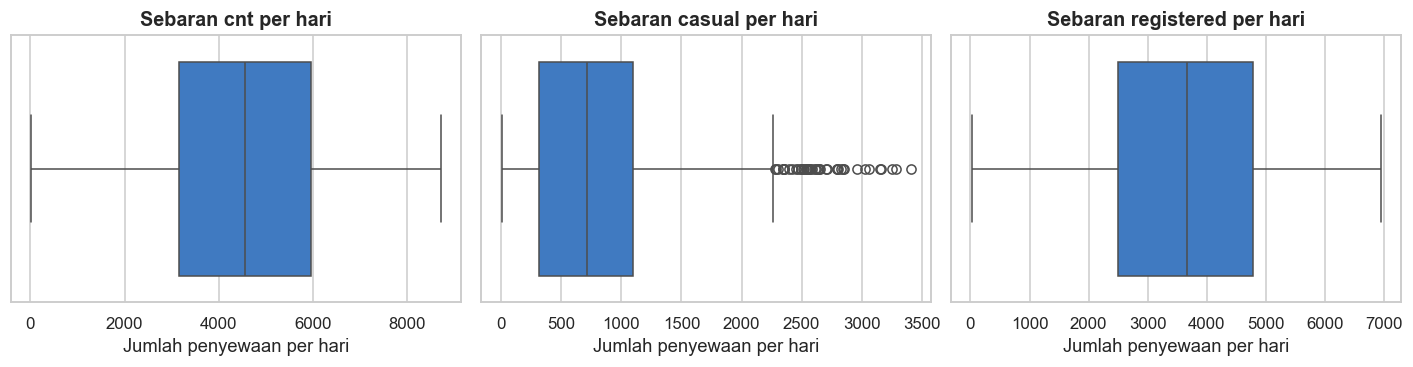

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, kolom in zip(axes, ["cnt", "casual", "registered"]):
    sns.boxplot(x=day_df[kolom], ax=ax, color=BLUE)
    ax.set_title(f"Sebaran {kolom} per hari")
    ax.set_xlabel("Jumlah penyewaan per hari")
plt.tight_layout()
plt.show()

In [17]:
q1, q3 = day_df["casual"].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
day_df.loc[day_df["casual"] > batas_atas, "workingday"].value_counts().rename({0: "Libur/Akhir Pekan", 1: "Hari Kerja"})

workingday
Libur/Akhir Pekan    43
Hari Kerja            1
Name: count, dtype: int64

**Steps to Take:**
- `cnt` dan `registered` tidak memiliki outlier. `casual` punya **44 outlier atas**, tetapi **43 di antaranya terjadi pada hari libur/akhir pekan**. Ini adalah pola perilaku yang nyata (lonjakan pengguna rekreasi), bukan kesalahan data.
- Solusi: outlier **dipertahankan** karena justru menjadi informasi penting untuk Pertanyaan 1. Hari ekstrem seperti 2012-10-29 (Badai Sandy, hanya 22 sewa) juga dipertahankan karena merupakan kejadian nyata.

**Insight (ringkasan Assessing Data):**

| Masalah | Kolom / Tabel | Tindakan di Cleaning |
|---|---|---|
| Tipe data salah | `dteday` (object) | Ubah ke `datetime` |
| Invalid value | `hum = 0` pada 2011-03-10 | Ganti `NaN` → interpolasi linear |
| Inaccurate value | Label `season` di Readme | Petakan ulang sesuai tanggal |
| Data kurang terbaca | Kode angka & nilai ternormalisasi | Beri label & kembalikan ke satuan asli |
| Missing records | 165 jam di `hour_df` | Tidak diimputasi, dicatat sebagai keterbatasan |
| Outlier | `casual` (44 hari) | Dipertahankan (pola nyata) |

### Cleaning Data

#### Memperbaiki tipe data `dteday`

In [18]:
for df in [day_df, hour_df]:
    df["dteday"] = pd.to_datetime(df["dteday"])

hour_df["datetime"] = hour_df["dteday"] + pd.to_timedelta(hour_df["hr"], unit="h")
day_df["dteday"].dtype, hour_df["datetime"].dtype

(dtype('<M8[us]'), dtype('<M8[us]'))

#### Memperbaiki *invalid value* `hum = 0`

In [19]:
day_df = day_df.sort_values("dteday").reset_index(drop=True)
hour_df = hour_df.sort_values("datetime").reset_index(drop=True)

for df in [day_df, hour_df]:
    df["hum"] = df["hum"].replace(0, np.nan).interpolate(method="linear")

print("Sisa hum = 0 :", (day_df["hum"] == 0).sum() + (hour_df["hum"] == 0).sum())
print("Sisa NaN hum :", day_df["hum"].isna().sum() + hour_df["hum"].isna().sum())
day_df.loc[day_df["dteday"].between("2011-03-09", "2011-03-11"), ["dteday", "hum"]]

Sisa hum = 0 : 0
Sisa NaN hum : 0


,dteday,hum
67,2011-03-09,0.775417
68,2011-03-10,0.712491
69,2011-03-11,0.649565


#### Memperbaiki label kategori (termasuk *inaccurate value* `season`)

In [20]:
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}
weather_map = {1: "Cerah/Berawan", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Hujan Lebat/Badai"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

for df in [day_df, hour_df]:
    df["season_label"] = df["season"].map(season_map)
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["weekday_label"] = df["weekday"].map(weekday_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Libur/Akhir Pekan")

day_df[["dteday", "season_label", "year", "weather_label", "weekday_label", "day_type"]].head()

,dteday,season_label,year,weather_label,weekday_label,day_type
0,2011-01-01,Winter,2011,Berkabut/Mendung,Sabtu,Libur/Akhir Pekan
1,2011-01-02,Winter,2011,Berkabut/Mendung,Minggu,Libur/Akhir Pekan
2,2011-01-03,Winter,2011,Cerah/Berawan,Senin,Hari Kerja
3,2011-01-04,Winter,2011,Cerah/Berawan,Selasa,Hari Kerja
4,2011-01-05,Winter,2011,Cerah/Berawan,Rabu,Hari Kerja


#### Mengembalikan variabel cuaca ke satuan aslinya

Sesuai Readme: `temp` dibagi 41, `atemp` dibagi 50, `hum` dibagi 100, `windspeed` dibagi 67. Kita kalikan kembali agar satuannya °C, %, dan km/jam.

In [21]:
for df in [day_df, hour_df]:
    df["temp_c"] = (df["temp"] * 41).round(1)
    df["atemp_c"] = (df["atemp"] * 50).round(1)
    df["hum_pct"] = (df["hum"] * 100).round(1)
    df["windspeed_kmh"] = (df["windspeed"] * 67).round(1)

day_df[["temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,temp_c,atemp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0
mean,20.3,23.7,62.9,12.8
std,7.5,8.1,14.1,5.2
min,2.4,4.0,18.8,1.5
25%,13.8,16.9,52.1,9.0
50%,20.4,24.3,62.7,12.1
75%,26.9,30.4,73.0,15.6
max,35.3,42.0,97.2,34.0


#### Menyimpan data bersih

In [22]:
kolom_day = ["dteday", "year", "mnth", "season_label", "holiday", "workingday", "day_type", "weekday_label",
             "weather_label", "temp_c", "atemp_c", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]
kolom_hour = ["datetime", "dteday", "year", "mnth", "hr", "season_label", "workingday", "day_type",
              "weather_label", "temp_c", "casual", "registered", "cnt"]

day_clean = day_df[kolom_day].copy()
hour_clean = hour_df[kolom_hour].copy()

day_clean.to_csv("dashboard/main_data.csv", index=False)
hour_clean.to_csv("dashboard/hour_data.csv", index=False)
day_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   dteday         731 non-null    datetime64[us]
 1   year           731 non-null    int64         
 2   mnth           731 non-null    int64         
 3   season_label   731 non-null    str           
 4   holiday        731 non-null    int64         
 5   workingday     731 non-null    int64         
 6   day_type       731 non-null    str           
 7   weekday_label  731 non-null    str           
 8   weather_label  731 non-null    str           
 9   temp_c         731 non-null    float64       
 10  atemp_c        731 non-null    float64       
 11  hum_pct        731 non-null    float64       
 12  windspeed_kmh  731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non-null    int

**Insight:**
- Semua tanggal kini bertipe `datetime`, sehingga bisa difilter per rentang waktu (dipakai juga di dashboard).
- Nilai `hum = 0` sudah diganti hasil interpolasi (contoh: 2011-03-10 kini bernilai di antara kelembapan 9 dan 11 Maret).
- Musim sekarang berlabel sesuai kalender belahan bumi utara (Winter = Des–Mar), dan suhu dalam °C sehingga hasil analisis bisa dibaca langsung oleh stakeholder.
- Data bersih disimpan ke `dashboard/main_data.csv` (harian) dan `dashboard/hour_data.csv` (per jam).

## Exploratory Data Analysis (EDA)

### Explore ringkasan statistik & tren tahunan

In [23]:
day_clean[["casual", "registered", "cnt", "temp_c", "hum_pct", "windspeed_kmh"]].describe().round(1)

,casual,registered,cnt,temp_c,hum_pct,windspeed_kmh
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,848.2,3656.2,4504.3,20.3,62.9,12.8
std,686.6,1560.3,1937.2,7.5,14.1,5.2
min,2.0,20.0,22.0,2.4,18.8,1.5
25%,315.5,2497.0,3152.0,13.8,52.1,9.0
50%,713.0,3662.0,4548.0,20.4,62.7,12.1
75%,1096.0,4776.5,5956.0,26.9,73.0,15.6
max,3410.0,6946.0,8714.0,35.3,97.2,34.0


In [24]:
tahunan = day_clean.groupby("year").agg(total_sewa=("cnt", "sum"), rata2_harian=("cnt", "mean"),
                                         total_casual=("casual", "sum"), total_registered=("registered", "sum"))
tahunan["pertumbuhan_%"] = (tahunan["total_sewa"].pct_change() * 100).round(1)
tahunan.round({"rata2_harian": 0, "pertumbuhan_%": 1})

,total_sewa,rata2_harian,total_casual,total_registered,pertumbuhan_%
year,,,,,
2011,1243103,3406.0,247252,995851,NaN
2012,2049576,5600.0,372765,1676811,64.9


In [25]:
bulanan = day_clean.groupby(["year", "mnth"])["cnt"].sum().unstack(0)
bulanan

year,2011,2012
mnth,,
1,38189,96744
2,48215,103137
3,64045,164875
4,94870,174224
5,135821,195865
6,143512,202830
7,141341,203607
8,136691,214503
9,127418,218573


**Insight:**
- Total penyewaan naik dari **1,24 juta (2011)** menjadi **2,05 juta (2012)**, tumbuh sekitar **64,9%**.
- Rata-rata penyewaan sekitar **4.504 sewa per hari**, dengan rentang 22 (Badai Sandy) sampai 8.714.
- Pola bulanan berbentuk "bukit": rendah di Januari–Februari, tinggi di Mei–September, lalu turun lagi menjelang akhir tahun.

### Explore Pertanyaan 1: hari kerja vs libur per tipe pengguna

In [26]:
q1 = day_clean.groupby("day_type").agg(jumlah_hari=("cnt", "size"),
                                       rata2_casual=("casual", "mean"),
                                       rata2_registered=("registered", "mean"),
                                       rata2_total=("cnt", "mean")).round(0)
q1

,jumlah_hari,rata2_casual,rata2_registered,rata2_total
day_type,,,,
Hari Kerja,500,607.0,3978.0,4585.0
Libur/Akhir Pekan,231,1371.0,2959.0,4330.0


In [27]:
proporsi = day_clean.groupby("day_type")[["casual", "registered"]].sum()
(proporsi.div(proporsi.sum(axis=1), axis=0) * 100).round(1)

,casual,registered
day_type,,
Hari Kerja,13.2,86.8
Libur/Akhir Pekan,31.7,68.3


**Insight:**
- Rata-rata total sewa harian hampir sama (≈4.585 hari kerja vs ≈4.330 hari libur), **tetapi komposisinya sangat berbeda**.
- Pengguna **casual** rata-rata **≈1.371/hari di hari libur**, lebih dari **2 kali lipat** hari kerja (≈607). Sebaliknya **registered** turun dari ≈3.978 ke ≈2.959.
- Porsi casual naik dari **13,2%** (hari kerja) menjadi **31,7%** (hari libur).

### Explore Pertanyaan 2: pola per jam tahun 2012

In [28]:
hour_2012 = hour_clean[hour_clean["year"] == 2012]
pola_jam = hour_2012.pivot_table(index="hr", columns="day_type", values="cnt", aggfunc="mean").round(0)
pola_jam.T

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Hari Kerja,44.0,19.0,10.0,5.0,6.0,32.0,128.0,367.0,605.0,302.0,...,230.0,256.0,372.0,656.0,617.0,438.0,312.0,229.0,169.0,109.0
Libur/Akhir Pekan,109.0,85.0,63.0,30.0,10.0,10.0,23.0,55.0,135.0,215.0,...,448.0,438.0,428.0,395.0,338.0,276.0,208.0,169.0,137.0,101.0


In [29]:
for tipe in pola_jam.columns:
    top3 = pola_jam[tipe].nlargest(3)
    print(f"{tipe:<18} → 3 jam tersibuk: {list(top3.index)} | rata-rata {list(top3.values)}")

Hari Kerja         → 3 jam tersibuk: [17, 18, 8] | rata-rata [np.float64(656.0), np.float64(617.0), np.float64(605.0)]
Libur/Akhir Pekan  → 3 jam tersibuk: [13, 12, 14] | rata-rata [np.float64(459.0), np.float64(451.0), np.float64(448.0)]


**Insight:**
- **Hari kerja** memiliki **dua puncak tajam**: pukul **08.00** (≈605 sewa/jam) dan pukul **17.00–18.00** (≈656 dan ≈617 sewa/jam), yaitu jam berangkat dan pulang kerja.
- **Hari libur** hanya punya **satu puncak landai** pada pukul **12.00–15.00** (≈440–460 sewa/jam).
- Jam paling sepi di kedua tipe hari adalah **03.00–05.00** (<35 sewa/jam).

### Explore Pertanyaan 3: cuaca × musim

In [30]:
day_clean["weather_label"].value_counts()

weather_label
Cerah/Berawan         463
Berkabut/Mendung      247
Hujan/Salju Ringan     21
Name: count, dtype: int64

In [31]:
q3 = day_clean.pivot_table(index="season_label", columns="weather_label", values="cnt", aggfunc="mean")
q3 = q3.reindex(["Winter", "Spring", "Summer", "Fall"])[["Cerah/Berawan", "Berkabut/Mendung", "Hujan/Salju Ringan"]]
q3["penurunan_hujan_vs_cerah_%"] = ((q3["Hujan/Salju Ringan"] / q3["Cerah/Berawan"] - 1) * 100)
q3.round(1)

weather_label,Cerah/Berawan,Berkabut/Mendung,Hujan/Salju Ringan,penurunan_hujan_vs_cerah_%
season_label,,,,
Winter,2811.1,2357.2,934.8,-66.7
Spring,5548.5,4236.7,1169.0,-78.9
Summer,5878.3,5222.5,2751.8,-53.2
Fall,5043.6,4654.0,1961.6,-61.1


In [32]:
day_clean.pivot_table(index="season_label", columns="weather_label", values="cnt", aggfunc="size").reindex(["Winter", "Spring", "Summer", "Fall"])

weather_label,Berkabut/Mendung,Cerah/Berawan,Hujan/Salju Ringan
season_label,,,
Winter,66,111,4
Spring,68,113,3
Summer,48,136,4
Fall,65,103,10


**Insight:**
- Secara keseluruhan rata-rata harian: cerah ≈4.877, mendung ≈4.036, hujan/salju ringan ≈1.803 sewa/hari.
- Penurunan saat hujan/salju ringan dibanding cerah terjadi di **semua musim**, berkisar **−53% (Summer)** sampai **−79% (Spring)**.
- **Catatan keterbatasan:** hanya ada **21 hari** hujan/salju ringan (3–6 hari per musim) dan **tidak ada** hari berkategori badai pada data harian, sehingga angka per musim perlu dibaca sebagai indikasi, bukan angka pasti.

## Visualization & Explanatory Analysis

Prinsip desain yang diterapkan pada semua grafik: judul menyatakan temuan utama, label sumbu bersatuan, sumbu batang dimulai dari nol, warna konsisten (biru = registered/hari kerja, oranye = casual/hari libur), warna abu-abu untuk elemen pendukung, dan anotasi langsung hanya pada angka penting.

### Pertanyaan 1: Bagaimana perbandingan rata-rata penyewaan harian hari kerja vs libur untuk pengguna casual dan registered (2011–2012)?

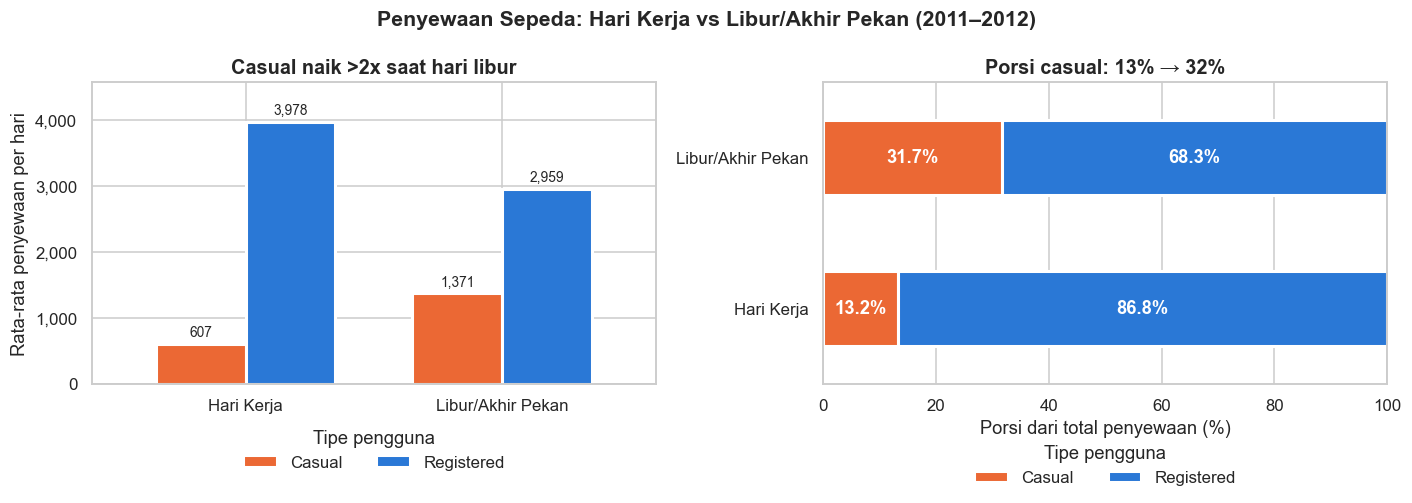

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Kiri: rata-rata sewa per hari per tipe pengguna
data_plot = q1[["rata2_casual", "rata2_registered"]].rename(columns={"rata2_casual": "Casual", "rata2_registered": "Registered"})
data_plot.plot(kind="bar", ax=axes[0], color=[ORANGE, BLUE], width=0.7, edgecolor="white", linewidth=2)
axes[0].set_title("Casual naik >2x saat hari libur")
axes[0].set_xlabel(None)
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].tick_params(axis="x", rotation=0)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:,.0f}", padding=3, fontsize=9)
axes[0].set_ylim(0, data_plot.values.max() * 1.15)
axes[0].legend(title="Tipe pengguna", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)

# Kanan: komposisi (%)
komposisi = proporsi.div(proporsi.sum(axis=1), axis=0) * 100
komposisi.columns = ["Casual", "Registered"]
komposisi.plot(kind="barh", stacked=True, ax=axes[1], color=[ORANGE, BLUE], edgecolor="white", linewidth=2)
axes[1].set_title("Porsi casual: 13% → 32%")
axes[1].set_xlabel("Porsi dari total penyewaan (%)")
axes[1].set_ylabel(None)
axes[1].set_xlim(0, 100)
for i, (c, r) in enumerate(komposisi.values):
    axes[1].text(c / 2, i, f"{c:.1f}%", ha="center", va="center", color="white", fontweight="bold")
    axes[1].text(c + r / 2, i, f"{r:.1f}%", ha="center", va="center", color="white", fontweight="bold")
axes[1].legend(title="Tipe pengguna", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)

fig.suptitle("Penyewaan Sepeda: Hari Kerja vs Libur/Akhir Pekan (2011–2012)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Insight:**
- Pengguna **registered** mendominasi hari kerja (pola komuter), sedangkan pengguna **casual** melonjak lebih dari dua kali lipat di hari libur (pola rekreasi).
- Artinya, hari libur adalah momen terbaik untuk menjangkau pengguna casual yang **belum menjadi member**.

### Pertanyaan 2: Jam berapa puncak penyewaan pada hari kerja vs hari libur (2012)?

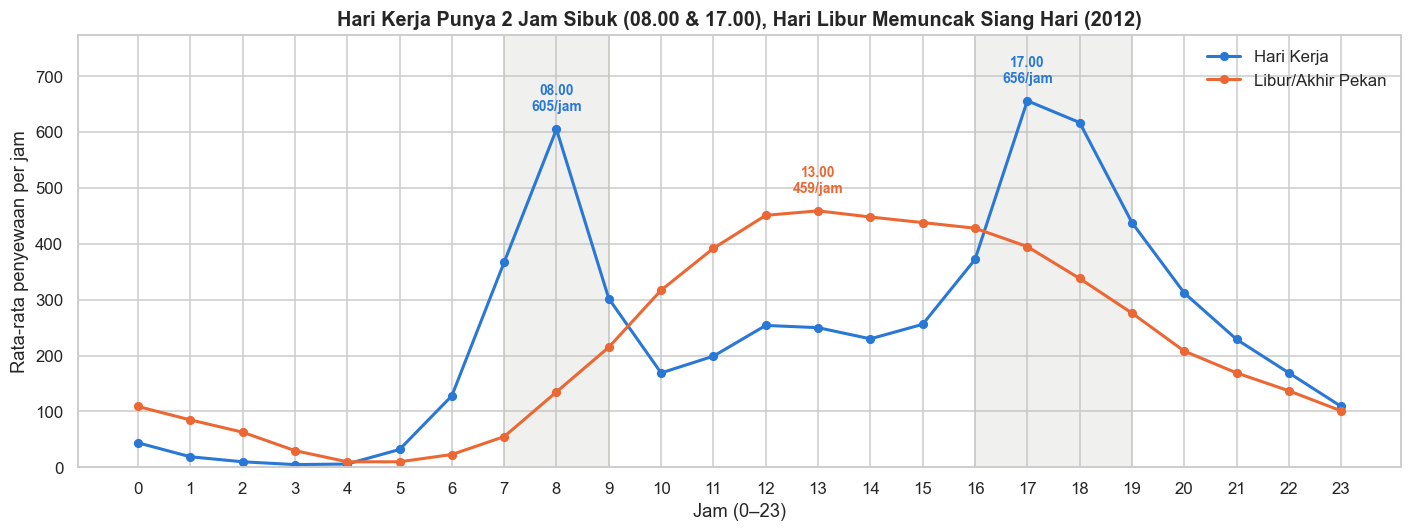

In [34]:
fig, ax = plt.subplots(figsize=(13, 5))
warna = {"Hari Kerja": BLUE, "Libur/Akhir Pekan": ORANGE}
for tipe in pola_jam.columns:
    ax.plot(pola_jam.index, pola_jam[tipe], marker="o", markersize=5, linewidth=2, color=warna[tipe], label=tipe)

# Anotasi jam puncak
for jam, tipe in [(8, "Hari Kerja"), (17, "Hari Kerja"), (13, "Libur/Akhir Pekan")]:
    nilai = pola_jam.loc[jam, tipe]
    ax.annotate(f"{jam:02d}.00\n{nilai:,.0f}/jam", xy=(jam, nilai), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=9, fontweight="bold", color=warna[tipe])

ax.axvspan(7, 9, color=GRAY, alpha=0.2)
ax.axvspan(16, 19, color=GRAY, alpha=0.2)
ax.set_title("Hari Kerja Punya 2 Jam Sibuk (08.00 & 17.00), Hari Libur Memuncak Siang Hari (2012)")
ax.set_xlabel("Jam (0–23)")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_xticks(range(0, 24))
ax.set_ylim(0, pola_jam.values.max() * 1.18)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Insight:**
- Area abu-abu menandai jam sibuk komuter (07.00–09.00 dan 16.00–19.00). Pada jam 08.00 dan 17.00 permintaan di hari kerja mencapai **≈600–650 sewa/jam**, dan pada pukul 08.00 permintaan hari kerja sekitar **4,5 kali** hari libur (≈605 vs ≈135 sewa/jam).
- Di hari libur, permintaan stabil tinggi pada **12.00–15.00**, sehingga jam sibuknya berbeda dari hari kerja.

### Pertanyaan 3: Seberapa besar penurunan penyewaan saat hujan/salju ringan dibanding cerah di tiap musim (2011–2012)?

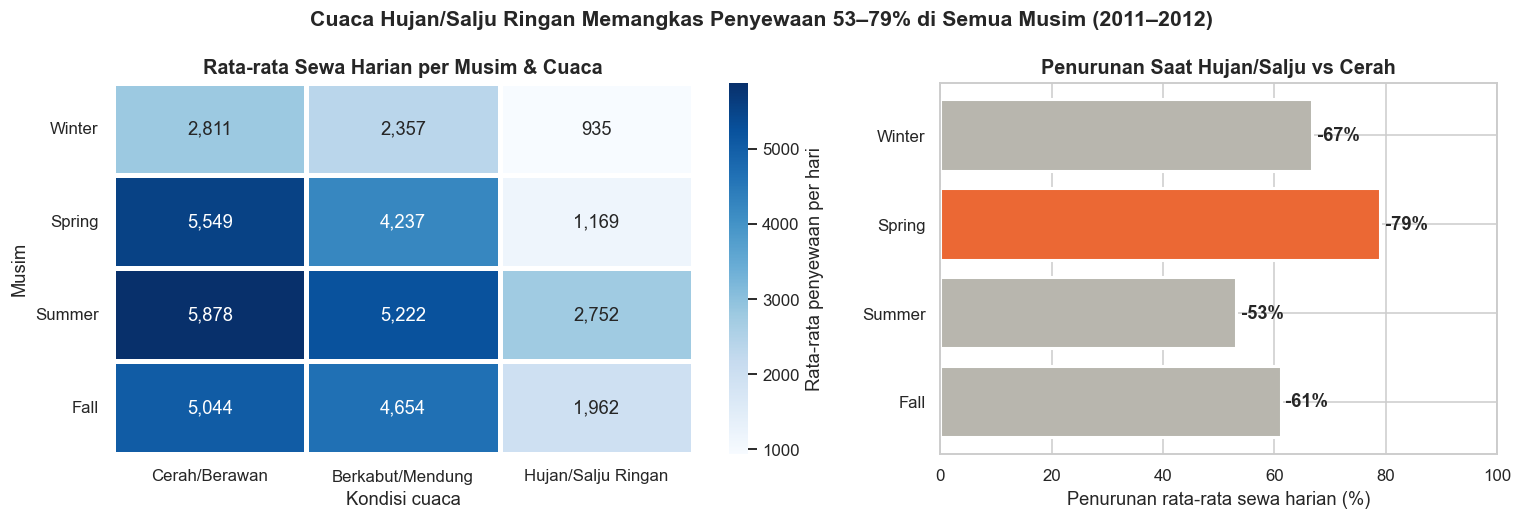

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

heat = q3[["Cerah/Berawan", "Berkabut/Mendung", "Hujan/Salju Ringan"]]
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="Blues", linewidths=2, linecolor="white",
            cbar_kws={"label": "Rata-rata penyewaan per hari"}, ax=axes[0])
axes[0].set_title("Rata-rata Sewa Harian per Musim & Cuaca")
axes[0].set_xlabel("Kondisi cuaca")
axes[0].set_ylabel("Musim")
axes[0].tick_params(axis="y", rotation=0)

turun = q3["penurunan_hujan_vs_cerah_%"]
bars = axes[1].barh(turun.index, turun.abs(), color=[ORANGE if v == turun.min() else GRAY for v in turun],
                    edgecolor="white", linewidth=2)
axes[1].bar_label(bars, labels=[f"-{v:.0f}%" for v in turun.abs()], padding=3, fontweight="bold")
axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_title("Penurunan Saat Hujan/Salju vs Cerah")
axes[1].set_xlabel("Penurunan rata-rata sewa harian (%)")
axes[1].set_ylabel(None)

fig.suptitle("Cuaca Hujan/Salju Ringan Memangkas Penyewaan 53–79% di Semua Musim (2011–2012)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Insight:**
- Heatmap menunjukkan pola yang sama di setiap musim: makin buruk cuaca (kolom ke kanan), makin terang warnanya, artinya permintaan makin rendah.
- Penurunan terbesar terjadi di **Spring (−79%)**, dan yang terkecil di **Summer (−53%)**. Winter adalah musim dengan permintaan terendah meskipun cuaca cerah (≈2.811/hari).
- Karena sampel hujan/salju per musim hanya 3–6 hari, besarnya persentase per musim perlu dipantau ulang dengan data yang lebih panjang.

## Analisis Lanjutan: Clustering Manual (Binning & Manual Grouping)

Teknik ini mengelompokkan data **tanpa algoritma machine learning**, menggunakan aturan bisnis (`pd.cut`) dan kuantil (`pd.qcut`). Tujuannya:
1. **Binning jam → segmen waktu** (Dini Hari, Pagi Sibuk, Siang, Sore Sibuk, Malam) untuk melihat kontribusi tiap segmen waktu per tipe pengguna (tahun 2012).
2. **Binning suhu (°C)** untuk mengetahui rentang suhu dengan permintaan tertinggi.
3. **Manual grouping hari berdasarkan tingkat permintaan** (Rendah/Sedang/Tinggi, masing-masing sepertiga hari) lalu memprofilkan karakteristik tiap kelompok.

### Cluster 1: Segmen waktu berdasarkan jam

In [36]:
bins_jam = [-1, 5, 9, 15, 19, 23]
label_jam = ["Dini Hari (00–05)", "Pagi Sibuk (06–09)", "Siang (10–15)", "Sore Sibuk (16–19)", "Malam (20–23)"]
hour_2012 = hour_2012.assign(segmen_waktu=pd.cut(hour_2012["hr"], bins=bins_jam, labels=label_jam))

segmen = hour_2012.groupby(["segmen_waktu", "day_type"], observed=True)[["casual", "registered"]].sum()
segmen_pct = (segmen.div(segmen.groupby(level="day_type").transform("sum")) * 100).round(1)
segmen_pct.unstack("day_type")

casual                   registered                  
day_type           Hari Kerja Libur/Akhir Pekan Hari Kerja Libur/Akhir Pekan
segmen_waktu                                                                
Dini Hari (00–05)         2.2               3.3        2.0               6.8
Pagi Sibuk (06–09)        9.5               5.7       26.4               9.1
Siang (10–15)            41.9              53.7       20.8              44.5
Sore Sibuk (16–19)       32.5              28.3       36.6              26.7
Malam (20–23)            13.8               9.0       14.2              12.8

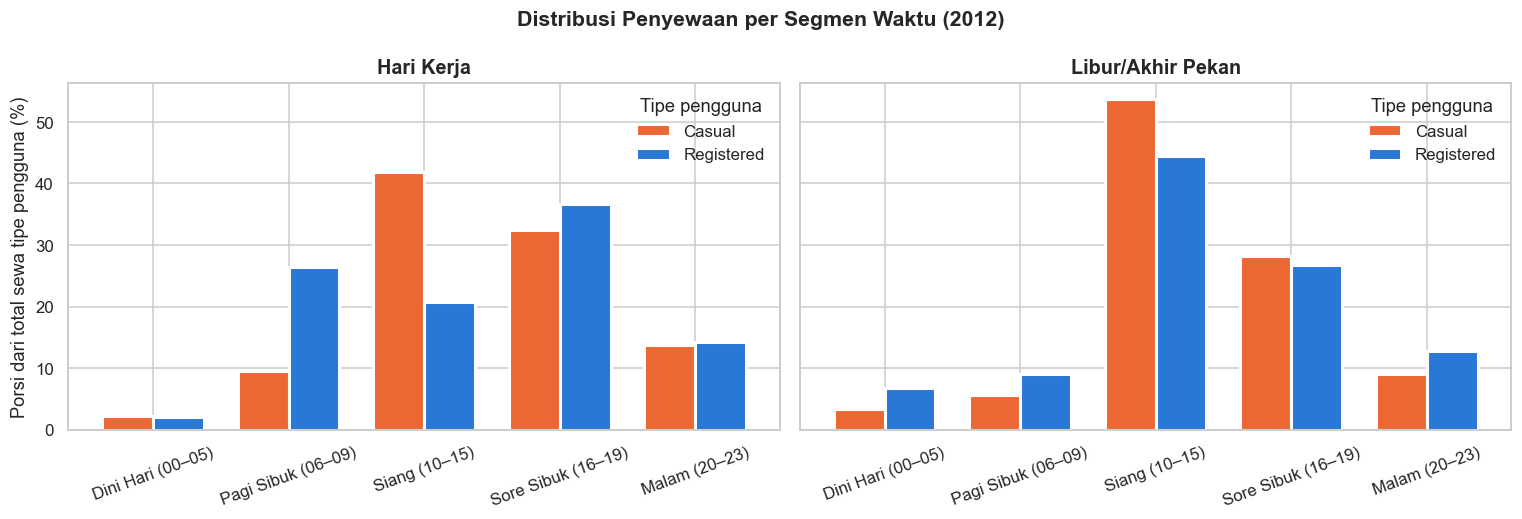

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, tipe in zip(axes, ["Hari Kerja", "Libur/Akhir Pekan"]):
    data = segmen_pct.xs(tipe, level="day_type")
    data.columns = ["Casual", "Registered"]
    data.plot(kind="bar", ax=ax, color=[ORANGE, BLUE], width=0.75, edgecolor="white", linewidth=2)
    ax.set_title(tipe)
    ax.set_xlabel(None)
    ax.set_ylabel("Porsi dari total sewa tipe pengguna (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Tipe pengguna", frameon=False)
fig.suptitle("Distribusi Penyewaan per Segmen Waktu (2012)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, pengguna **registered** terkonsentrasi di segmen **Pagi Sibuk** dan **Sore Sibuk** (pola komuter), sedangkan **casual** paling banyak di **Siang** dan **Sore**.
- Pada hari libur, kedua tipe pengguna memuncak di segmen **Siang (10–15)**.

### Cluster 2: Binning suhu

In [38]:
bins_suhu = [0, 10, 20, 30, 41]
label_suhu = ["Dingin (≤10°C)", "Sejuk (10–20°C)", "Hangat (20–30°C)", "Panas (>30°C)"]
day_clean["kategori_suhu"] = pd.cut(day_clean["temp_c"], bins=bins_suhu, labels=label_suhu)
suhu = day_clean.groupby("kategori_suhu", observed=True).agg(jumlah_hari=("cnt", "size"), rata2_sewa=("cnt", "mean")).round(0)
suhu

,jumlah_hari,rata2_sewa
kategori_suhu,,
Dingin (≤10°C),60,1678.0
Sejuk (10–20°C),299,3692.0
Hangat (20–30°C),300,5662.0
Panas (>30°C),72,5410.0


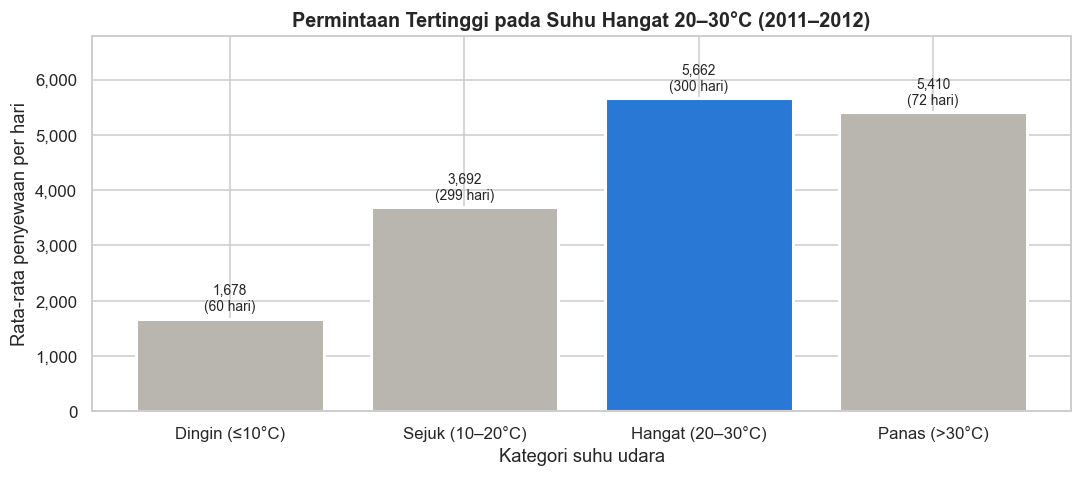

In [39]:
fig, ax = plt.subplots(figsize=(10, 4.5))
warna_suhu = [BLUE if v == suhu["rata2_sewa"].max() else GRAY for v in suhu["rata2_sewa"]]
bars = ax.bar(suhu.index.astype(str), suhu["rata2_sewa"], color=warna_suhu, edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{v:,.0f}\n({n} hari)" for v, n in zip(suhu["rata2_sewa"], suhu["jumlah_hari"])], padding=3, fontsize=9)
ax.set_title("Permintaan Tertinggi pada Suhu Hangat 20–30°C (2011–2012)")
ax.set_xlabel("Kategori suhu udara")
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_ylim(0, suhu["rata2_sewa"].max() * 1.2)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata sewa pada suhu **dingin (≤10°C)** hanya ≈1.678/hari, melonjak menjadi ≈5.662/hari pada suhu **hangat (20–30°C)**, lalu sedikit turun saat **panas (>30°C)**.
- Hubungan suhu dan permintaan **tidak linear**: terlalu panas juga sedikit menurunkan minat bersepeda.

### Cluster 3: Manual grouping hari berdasarkan tingkat permintaan

In [40]:
day_clean["tingkat_permintaan"] = pd.qcut(day_clean["cnt"], q=3, labels=["Rendah", "Sedang", "Tinggi"])
batas = day_clean.groupby("tingkat_permintaan", observed=True)["cnt"].agg(["min", "max", "size"])
batas

,min,max,size
tingkat_permintaan,,,
Rendah,22,3740,244
Sedang,3744,5312,244
Tinggi,5315,8714,243


In [41]:
profil = day_clean.groupby("tingkat_permintaan", observed=True).agg(
    rata2_sewa=("cnt", "mean"),
    rata2_suhu_c=("temp_c", "mean"),
    rata2_kelembapan=("hum_pct", "mean"),
    porsi_hari_kerja_pct=("workingday", lambda x: x.mean() * 100),
    porsi_tahun_2012_pct=("year", lambda x: (x == 2012).mean() * 100),
    porsi_cuaca_cerah_pct=("weather_label", lambda x: (x == "Cerah/Berawan").mean() * 100),
).round(1)
profil

,rata2_sewa,rata2_suhu_c,rata2_kelembapan,porsi_hari_kerja_pct,porsi_tahun_2012_pct,porsi_cuaca_cerah_pct
tingkat_permintaan,,,,,,
Rendah,2312.1,13.7,63.5,62.3,25.0,49.6
Sedang,4522.2,22.9,64.6,73.0,30.7,65.6
Tinggi,6687.7,24.4,60.5,70.0,94.7,74.9


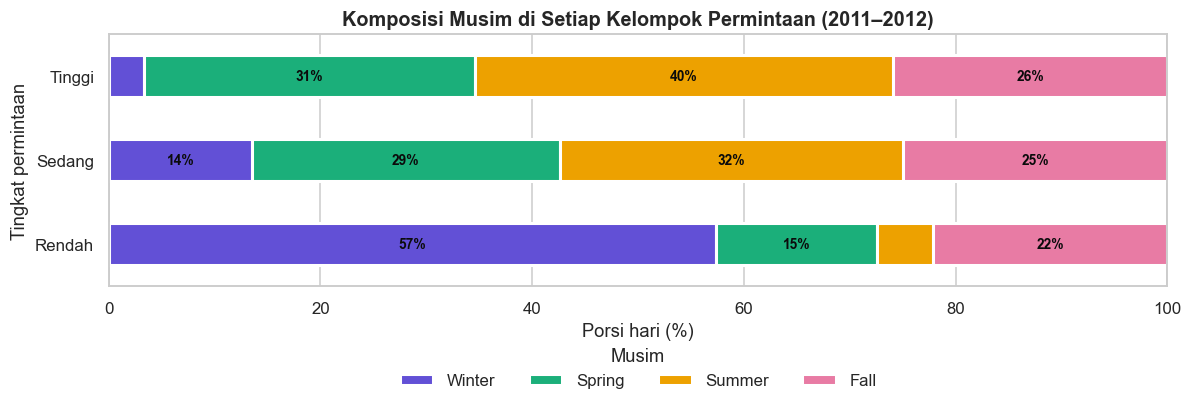

In [42]:
musim_cluster = pd.crosstab(day_clean["tingkat_permintaan"], day_clean["season_label"], normalize="index")[["Winter", "Spring", "Summer", "Fall"]] * 100

fig, ax = plt.subplots(figsize=(11, 4))
musim_cluster.plot(kind="barh", stacked=True, ax=ax, color=["#6250d6", "#1baf7a", "#eda100", "#e87ba4"], edgecolor="white", linewidth=2)
for i, baris in enumerate(musim_cluster.values):
    kiri = 0
    for nilai in baris:
        if nilai >= 8:
            ax.text(kiri + nilai / 2, i, f"{nilai:.0f}%", ha="center", va="center", color="#0b0b0b", fontweight="bold", fontsize=9)
        kiri += nilai
ax.set_title("Komposisi Musim di Setiap Kelompok Permintaan (2011–2012)")
ax.set_xlabel("Porsi hari (%)")
ax.set_ylabel("Tingkat permintaan")
ax.set_xlim(0, 100)
ax.legend(title="Musim", frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4)
plt.tight_layout()
plt.show()

**Insight:**
- Hari dibagi menjadi tiga kelompok sama besar (±244 hari): **Rendah** (22–3.740 sewa), **Sedang** (3.744–5.312), dan **Tinggi** (5.315–8.714).
- Kelompok **Tinggi**: **94,7%** harinya berada di tahun **2012**, rata-rata suhu **24,4°C**, 74,9% cerah, dan hanya **3%** hari Winter.
- Kelompok **Rendah**: **57%** harinya adalah **Winter**, rata-rata suhu **13,7°C**, hanya 49,6% cerah, dan 75% berada di tahun 2011.
- Porsi hari kerja di ketiga kelompok tidak jauh berbeda (62–73%), sehingga **musim/suhu, cuaca, dan pertumbuhan tahunan** lebih menentukan tingkat permintaan harian dibanding jenis hari.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama 2011–2012, rata-rata total sewa harian di hari kerja (≈4.585) dan hari libur (≈4.330) hampir sama, tetapi komposisinya berbeda tajam. Pengguna **casual** naik dari ≈607 menjadi ≈1.371 sewa/hari (**>2 kali lipat**) di hari libur, sehingga porsinya naik dari **13,2% menjadi 31,7%**. Sebaliknya pengguna **registered** turun dari ≈3.978 menjadi ≈2.959 sewa/hari. Hari kerja digerakkan oleh komuter terdaftar, hari libur oleh pengguna rekreasi.
- **Conclusion pertanyaan 2:** Pada tahun 2012, hari kerja memiliki **dua jam puncak**, yaitu **08.00 (≈605 sewa/jam)** dan **17.00–18.00 (≈656 dan ≈617 sewa/jam)**. Hari libur memiliki **satu puncak landai** pada **12.00–15.00 (≈440–460 sewa/jam)**. Jam paling sepi di keduanya adalah 03.00–05.00.
- **Conclusion pertanyaan 3:** Cuaca hujan/salju ringan menurunkan rata-rata sewa harian di **semua musim**, sebesar **−53% (Summer) sampai −79% (Spring)** dibanding cuaca cerah. Winter tetap menjadi musim terendah bahkan saat cerah (≈2.811/hari). Temuan ini didukung oleh analisis lanjutan: permintaan tertinggi berada pada suhu hangat 20–30°C. *Keterbatasan:* hanya 21 hari hujan/salju ringan dalam data, sehingga besaran persentase per musim bersifat indikatif.
- **Gambaran umum:** total penyewaan tumbuh **≈64,9%** dari 2011 ke 2012.

**Rekomendasi Action Item:**
- **Promo konversi member di akhir pekan (dari Pertanyaan 1):** jalankan promo "coba member" (misalnya diskon bulan pertama) yang ditampilkan saat pengguna casual menyewa pada Sabtu–Minggu pukul 10.00–16.00, karena pada saat itulah porsi pengguna casual paling besar (≈32%). Ukur keberhasilan dari kenaikan jumlah registered baru per bulan.
- **Redistribusi armada sebelum jam sibuk (dari Pertanyaan 2):** pada hari kerja, pastikan stasiun di area perkantoran dan permukiman sudah terisi sebelum **07.00** dan **16.00**. Jadwalkan perawatan/servis sepeda pada **00.00–05.00** (hari kerja) dan pagi hari libur sebelum 09.00, saat permintaan paling rendah.
- **Armada adaptif terhadap cuaca (dari Pertanyaan 3):** saat prakiraan cuaca hujan/salju ringan, kurangi sepeda yang disiagakan dan alihkan tim lapangan untuk perawatan, karena permintaan bisa turun lebih dari separuh. Fokuskan kapasitas penuh dan kampanye pemasaran pada **Spring–Fall** dengan suhu 20–30°C.